# Практика 5

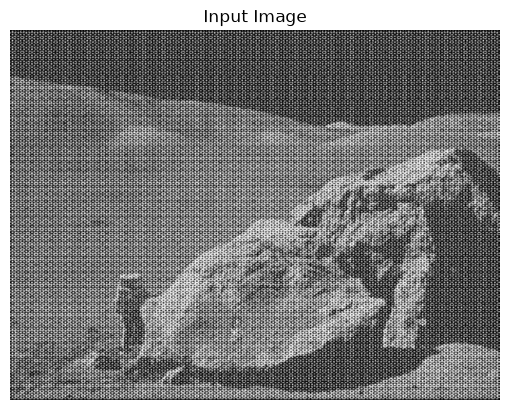

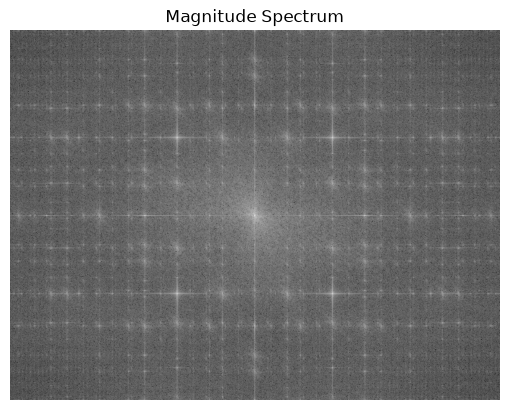

In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt


def showpic(image, title, cmap='gray'):
    plt.figure()
    plt.imshow(image, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()


def magnitude_log(dft_shift):
    mag = cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
    return 20 * np.log(mag + 1)


img = cv.imread('source/periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
showpic(img, 'Input Image')

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
showpic(magnitude_log(dft_shift), 'Magnitude Spectrum')

# Задание 1

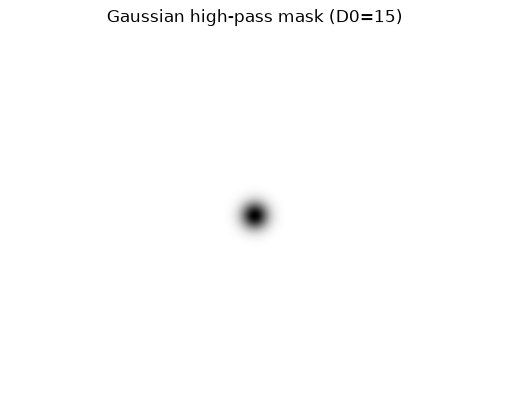

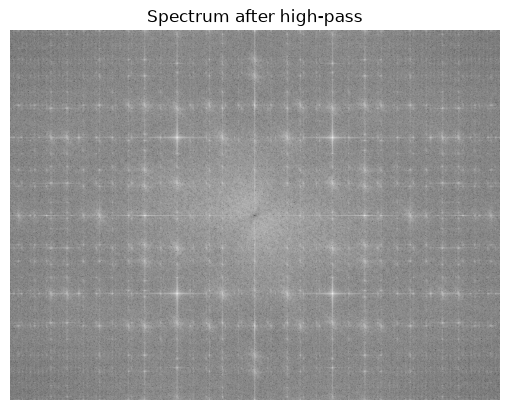

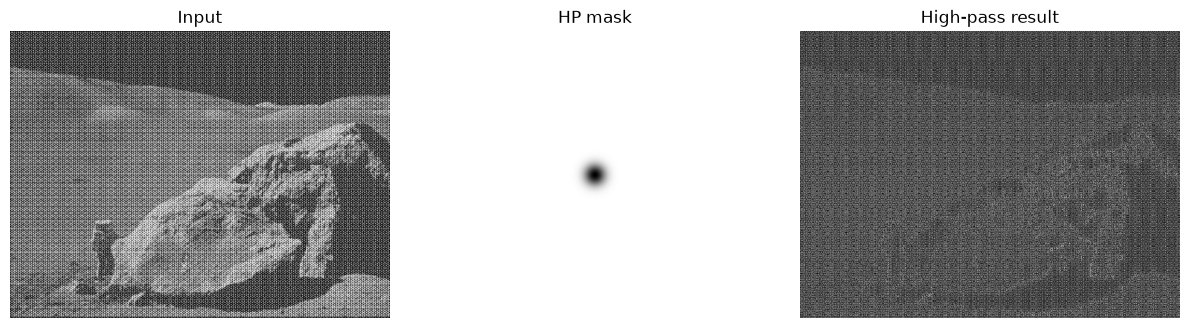

In [2]:
def gaussian_highpass_mask(shape, d0):
    rows, cols = shape
    cx, cy = rows // 2, cols // 2
    u = np.arange(rows) - cx
    v = np.arange(cols) - cy
    u, v = np.meshgrid(u, v, indexing='ij')
    d2 = u ** 2 + v ** 2
    hp = 1.0 - np.exp(-d2 / (2.0 * d0 ** 2))
    mask = np.zeros((rows, cols, 2), np.float32)
    mask[:, :, 0] = hp
    mask[:, :, 1] = hp
    return mask


D0 = 15
hp_mask = gaussian_highpass_mask(img.shape, D0)
showpic(hp_mask[:, :, 0], f'Gaussian high-pass mask (D0={D0})')

dft_hp = dft_shift * hp_mask
showpic(magnitude_log(dft_hp), 'Spectrum after high-pass')

f_ishift_hp = np.fft.ifftshift(dft_hp)
img_hp = cv.idft(f_ishift_hp)
img_hp = cv.magnitude(img_hp[:, :, 0], img_hp[:, :, 1])

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(img, cmap='gray'); plt.title('Input'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(hp_mask[:, :, 0], cmap='gray'); plt.title('HP mask'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(img_hp, cmap='gray'); plt.title('High-pass result'); plt.axis('off')
plt.tight_layout(); plt.show()

# Задание 2

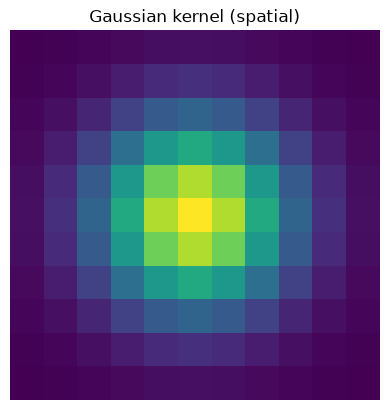

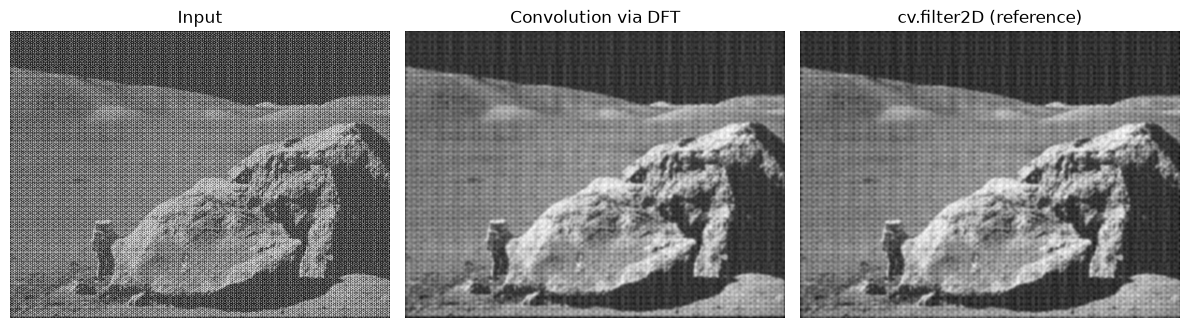

In [3]:
def gaussian_kernel_2d(ksize, sigma):
    ax = np.arange(-(ksize // 2), ksize // 2 + 1)
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()


def conv_via_dft(img, kernel):
    k_h, k_w = kernel.shape
    h, w = img.shape

    kernel_padded = np.zeros_like(img, dtype=np.float32)
    kernel_padded[:k_h, :k_w] = kernel
    kernel_padded = np.roll(kernel_padded, (-k_h // 2, -k_w // 2), axis=(0, 1))

    dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
    dft_k = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)

    a, b = dft_img[:, :, 0], dft_img[:, :, 1]
    c, d = dft_k[:, :, 0], dft_k[:, :, 1]

    prod = np.zeros_like(dft_img)
    prod[:, :, 0] = a * c - b * d
    prod[:, :, 1] = a * d + b * c

    conv = cv.idft(prod)
    conv = cv.magnitude(conv[:, :, 0], conv[:, :, 1])

    conv = conv / (h * w)
    return np.clip(conv, 0, 255).astype(np.uint8)


k = gaussian_kernel_2d(ksize=11, sigma=2.0)
showpic(k, 'Gaussian kernel (spatial)', cmap='viridis')

img_conv_dft = conv_via_dft(img, k)
img_conv_ref = cv.filter2D(img, -1, k.astype(np.float32))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(img, cmap='gray'); plt.title('Input'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(img_conv_dft, cmap='gray'); plt.title('Convolution via DFT'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(img_conv_ref, cmap='gray'); plt.title('cv.filter2D (reference)'); plt.axis('off')
plt.tight_layout(); plt.show()

# Задание 3

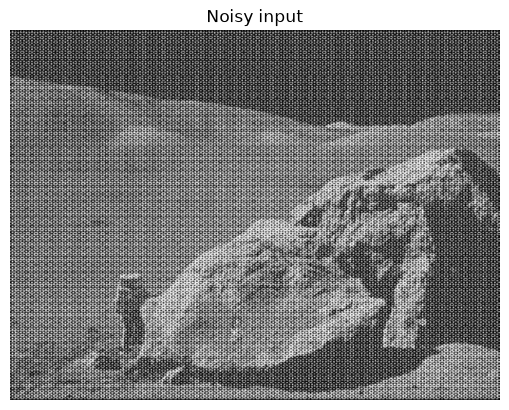

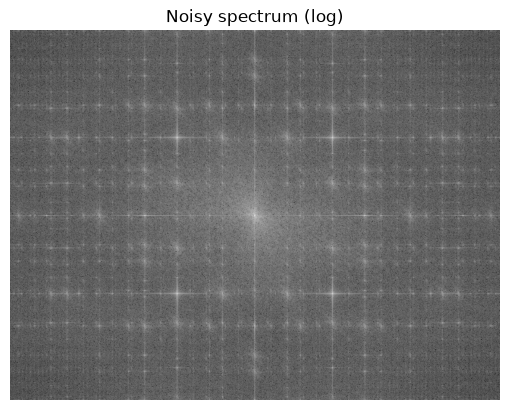

Found peaks: 533
Coords (y, x): [[297 393]
 [297 216]
 [297 570]
 ...
 [525 720]
 [194 747]
 [400  39]]


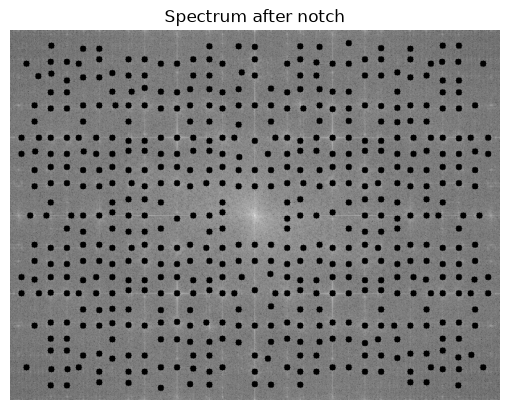

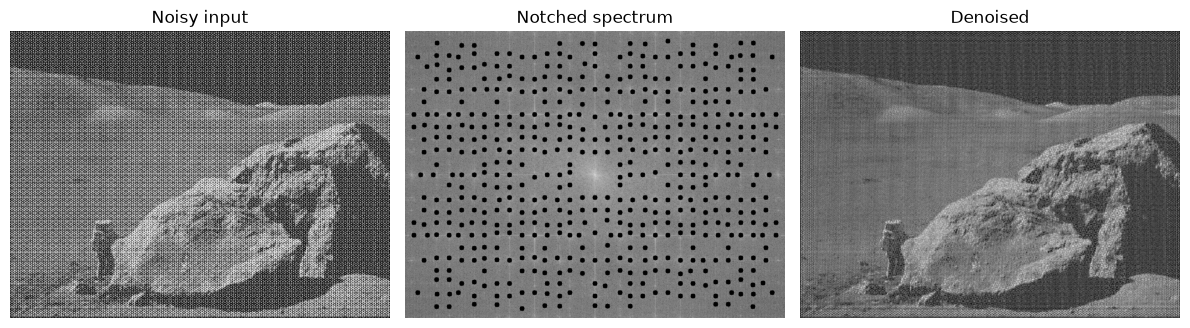

In [4]:
from skimage.feature import peak_local_max

noisy = cv.imread('source/periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
showpic(noisy, 'Noisy input')

dft_noisy = cv.dft(np.float32(noisy), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft_noisy)

magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)
showpic(magnitude_spectrum, 'Noisy spectrum (log)')

rows, cols = noisy.shape

local_max = peak_local_max(magnitude_spectrum, min_distance=15, threshold_abs=200)
print(f"Found peaks: {len(local_max)}")
print("Coords (y, x):", local_max)

mask = np.ones((rows, cols, 2), dtype=np.uint8)
center_x, center_y = rows // 2, cols // 2

for peak in local_max:
    y, x = peak
    distance = np.sqrt((x - center_y) ** 2 + (y - center_x) ** 2)
    if distance > 40:
        cv.circle(mask, (x, y), 5, (0, 0), -1)

dft_shift = dft_shift * mask

filtered_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)
showpic(filtered_spectrum, 'Spectrum after notch')

img_idft = cv.idft(np.fft.ifftshift(dft_shift))
img_clean = cv.magnitude(img_idft[:, :, 0], img_idft[:, :, 1])

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(noisy, cmap='gray'); plt.title('Noisy input'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(filtered_spectrum, cmap='gray'); plt.title('Notched spectrum'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(img_clean, cmap='gray'); plt.title('Denoised'); plt.axis('off')
plt.tight_layout(); plt.show()